# 00 · Summary: every reported number at a glance

> **Provenance.** Built with the `repro-notebook` workflow (one executed notebook per experiment,
> every reported number checked against the produced one). Target paper: *Conversational Relevance in the
> Conjunction Fallacy Is Represented in Language Models* (`docs/paper/main_A.tex` in the authors' working
> repository; the released copy of the manuscript is the submission PDF). Companion documents:
> `REPRODUCTION_MANIFEST.md` (paper number → source CSV → producing script) and `REPRODUCTION_REPORT.md`
> (aggregated verdicts). Status legend: ✅ reproduced to the reported precision · ❌ does not match ·
> ⚠ presence check only · ⛔ cannot be recomputed from the released files.

This notebook aggregates the check tables written by notebooks 01–05 (`notebooks/_checks_0*.csv`) and shows the paper's
figures. Run the five experiment notebooks first (`python3 notebooks/build_notebooks.py --execute` does so in order).

In [1]:
import sys, warnings
sys.path.insert(0, str(__import__('pathlib').Path.cwd() / 'notebooks'))
sys.path.insert(0, '.')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from repro_utils import *
pd.set_option('display.width', 200, 'display.max_columns', 40, 'display.max_rows', 60,
              'display.float_format', lambda v: f'{v:,.4f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25,
                     'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})
print('repository root:', ROOT.name)

repository root: release


In [2]:
import glob
parts = [pd.read_csv(p).assign(notebook=Path(p).stem.replace('_checks_', '')) for p in sorted(glob.glob(str(ROOT / 'notebooks' / '_checks_0[1-5].csv')))]
allc = pd.concat(parts, ignore_index=True)
counts = allc.status.value_counts()
display(Markdown('### Verdicts\n\n' + ' · '.join(f'**{k}** {v}' for k, v in counts.items()) + f'  (of {len(allc)} checks)'))
display(allc.groupby(['notebook', 'status']).size().unstack(fill_value=0))

### Verdicts

**✅** 135 · **❌** 18 · **⚠** 12 · **≈** 5 · **⛔** 5  (of 175 checks)

status,≈,⚠,⛔,✅,❌
notebook,,,,,
01,5,3,0,44,2
02,0,3,0,28,0
03,0,1,0,23,3
04,0,1,1,19,0
05,0,4,4,21,13


## Main-text numbers (Results ¶1–¶8)

In [3]:
main = allc[allc.section.str.startswith('Results')]
display(main[['id', 'section', 'analysis', 'reported', 'produced', 'status']].style.hide(axis='index'))

id,section,analysis,reported,produced,status
A1,Results ¶1,"DoD R|N positive, 15 items",12/12,12/12,✅
A1,Results ¶1,"DoD R|N Holm-significant, 15 items",12/12,12/12,✅
A1,Results ¶1,"mean DoD R|N conj, 15 items",0.313,+0.3125,❌
A1,Results ¶1,"DoD R|N Holm-significant, 165 items",12/12,12/12,✅
A1,Results ¶1,"mean DoD R|N conj, 165 items",0.356,+0.3560,✅
A2,Results ¶1,"worst LOIO fold still p<.05, 15 items",12/12,12/12,✅
A3,Results ¶1,"DoD R|I Holm-significant, 15 items",12/12,12/12,✅
A3,Results ¶1,"DoD I|N Holm-significant, 15 items",0/12,0/12,✅
A3,Results ¶1,"relevance share of full effect, 15 items",58–85,58–85,✅
A3,Results ¶1,"DoD R|I Holm-significant, 165 items",12/12,12/12,✅


## Appendix, tables, figures and deviations

In [4]:
rest = allc[~allc.section.str.startswith('Results')]
display(rest[['id', 'section', 'analysis', 'reported', 'produced', 'status', 'note']].style.hide(axis='index'))

id,section,analysis,reported,produced,status,note
A9,Discussion ¶1,banks agree to within 0.05 DoD (165 − 15),0.05,+0.050,✅,"|difference| = 0.044, within the stated 0.05"
A3,Table tab:decomp,"mean DoD R|I, 15 items",0.215,+0.2149,✅,nan
A3,Table tab:decomp,"mean DoD I|N, 15 items",0.097,+0.0975,✅,nan
A3,Table tab:decomp,"mean DoD R|N, 15 items",0.312,+0.3123,✅,the paper prints 0.312 in the table and 0.313 in Results ¶1 for the same quantity
A3,Table tab:decomp,"mean DoD R|I, 165 items",0.164,+0.1637,✅,nan
A3,Table tab:decomp,"mean DoD I|N, 165 items",0.192,+0.1923,✅,nan
A3,Table tab:decomp,"mean DoD R|N, 165 items",0.356,+0.3560,✅,nan
A7,working notes only,"mediation C, 15 items (not in paper)","-0.080 [-0.243, +0.141]","-0.080 [-0.243, +0.141]",⚠,presence check; not a numeric match
A7,working notes only,"mediation C, 165 items (not in paper)","+0.094 [+0.053, +0.141]","+0.094 [+0.053, +0.142]",⚠,presence check; not a numeric match
A10,Appendix app:large,mediation rho: sign agrees across banks,1/6,1/6,✅,nan


## Everything that did not reproduce exactly (❌), could not be recomputed (⛔) or is a presence check (⚠)

In [5]:
odd = allc[allc.status != '✅']
display(odd[['notebook', 'id', 'analysis', 'reported', 'produced', 'status', 'note']].style.hide(axis='index'))
allc.to_csv(ROOT / 'notebooks' / '_checks_all.csv', index=False); print('saved notebooks/_checks_all.csv')

notebook,id,analysis,reported,produced,status,note
01,A1,"mean DoD R|N conj, 15 items",0.313,+0.3125,❌,"exact mean 0.31246, which rounds to 0.312; Results ¶1 prints 0.313 and Table tab:decomp prints 0.312"
01,A6,"confounding rho, 15 items: CI high",+0.040,+0.0423,≈,"seed-dependent bootstrap, within 0.01 of the reported bound"
01,A6,"confounding C, 15 items: CI high",+0.167,+0.1690,≈,"seed-dependent bootstrap, within 0.01 of the reported bound"
01,A7,"mediation rho, 15 items: CI low",-0.394,-0.3958,≈,"seed-dependent bootstrap, within 0.01 of the reported bound"
01,A7,"mediation rho, 15 items: CI high",-0.177,-0.1801,≈,"seed-dependent bootstrap, within 0.01 of the reported bound"
01,A7,"mediation C, 15 items (not in paper)","-0.080 [-0.243, +0.141]","-0.080 [-0.243, +0.141]",⚠,presence check; not a numeric match
01,A6,"confounding rho, 165 items: CI low",-0.091,-0.0929,≈,"seed-dependent bootstrap, within 0.01 of the reported bound"
01,A7,"mediation C, 165 items (not in paper)","+0.094 [+0.053, +0.141]","+0.094 [+0.053, +0.142]",⚠,presence check; not a numeric match
01,A10,every mediation interval overlaps its counterpart,yes,no,⚠,presence check; not a numeric match
01,A8,wording correlation over items (mean of six per-model Spearman ρ),.96,+0.929,❌,"median 0.95, pooled 0.92; Phi-4-mini-reasoning alone is 0.77. The .96 in the paper was quoted from the eight-model run"


saved notebooks/_checks_all.csv


## Figures as printed

**fig1_behavior.png**

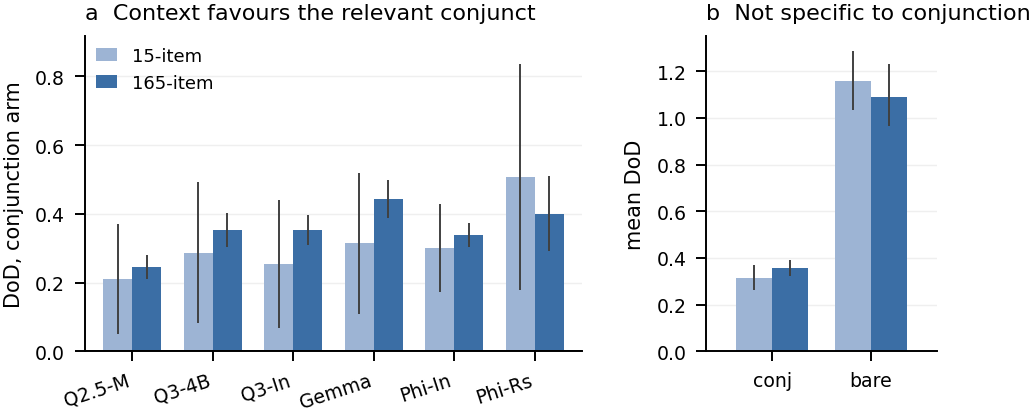

**fig2_representation.png**

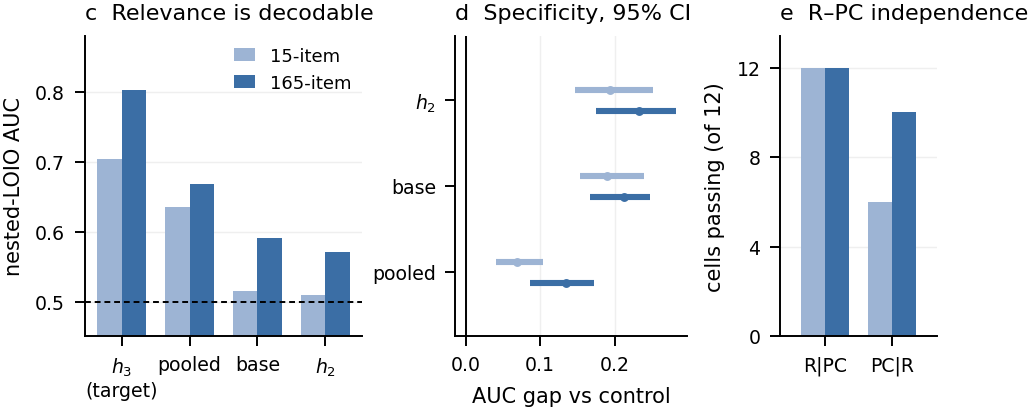

**fig3_cf_intervention.png**

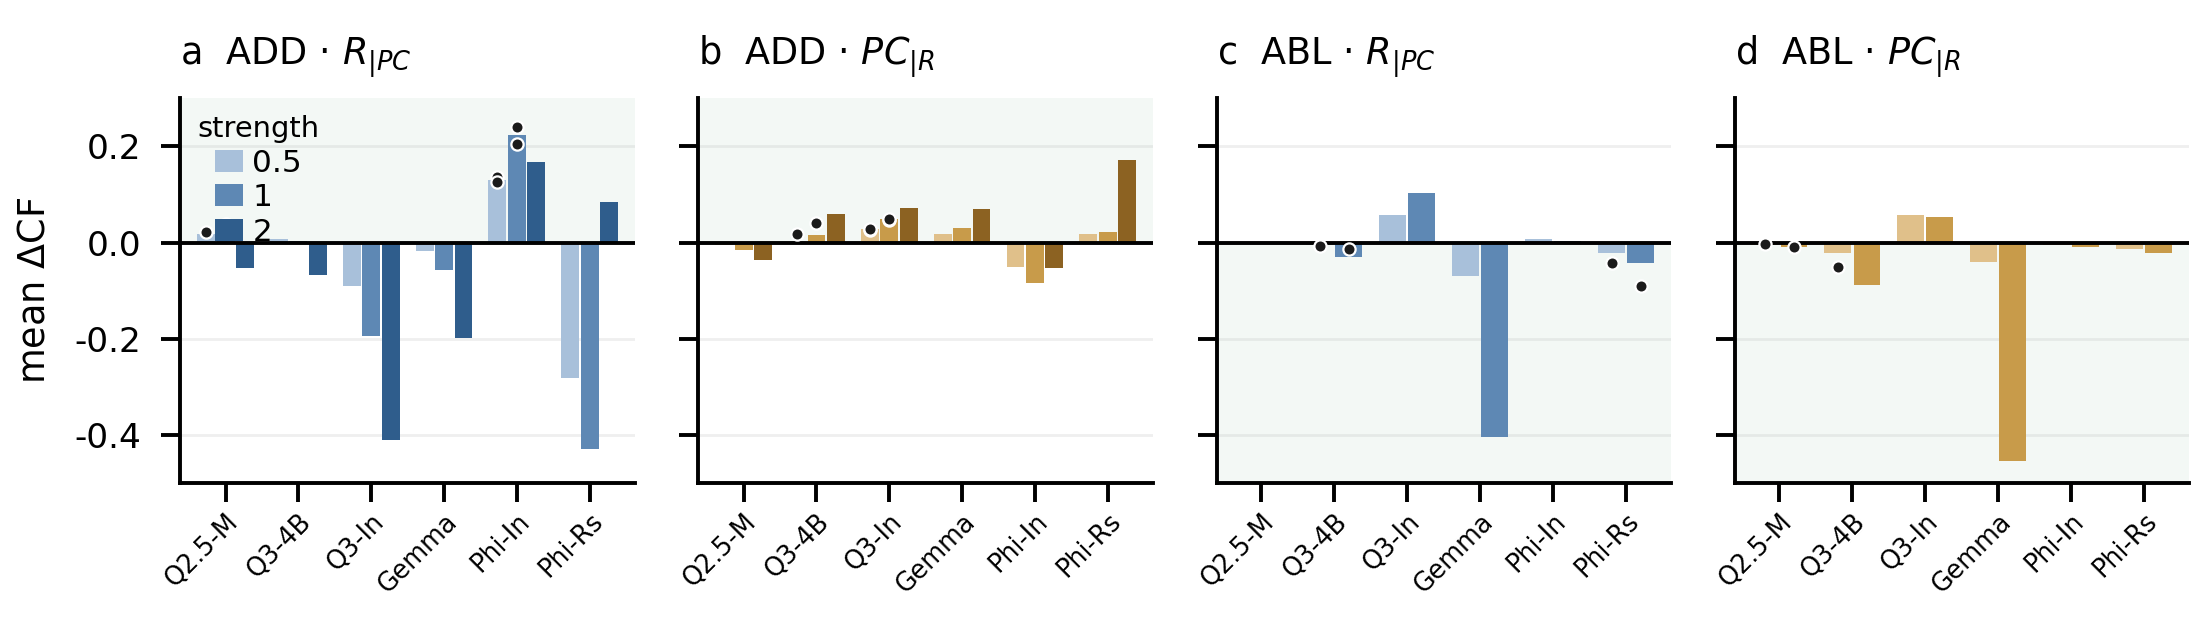

**figS1_decoding.png**

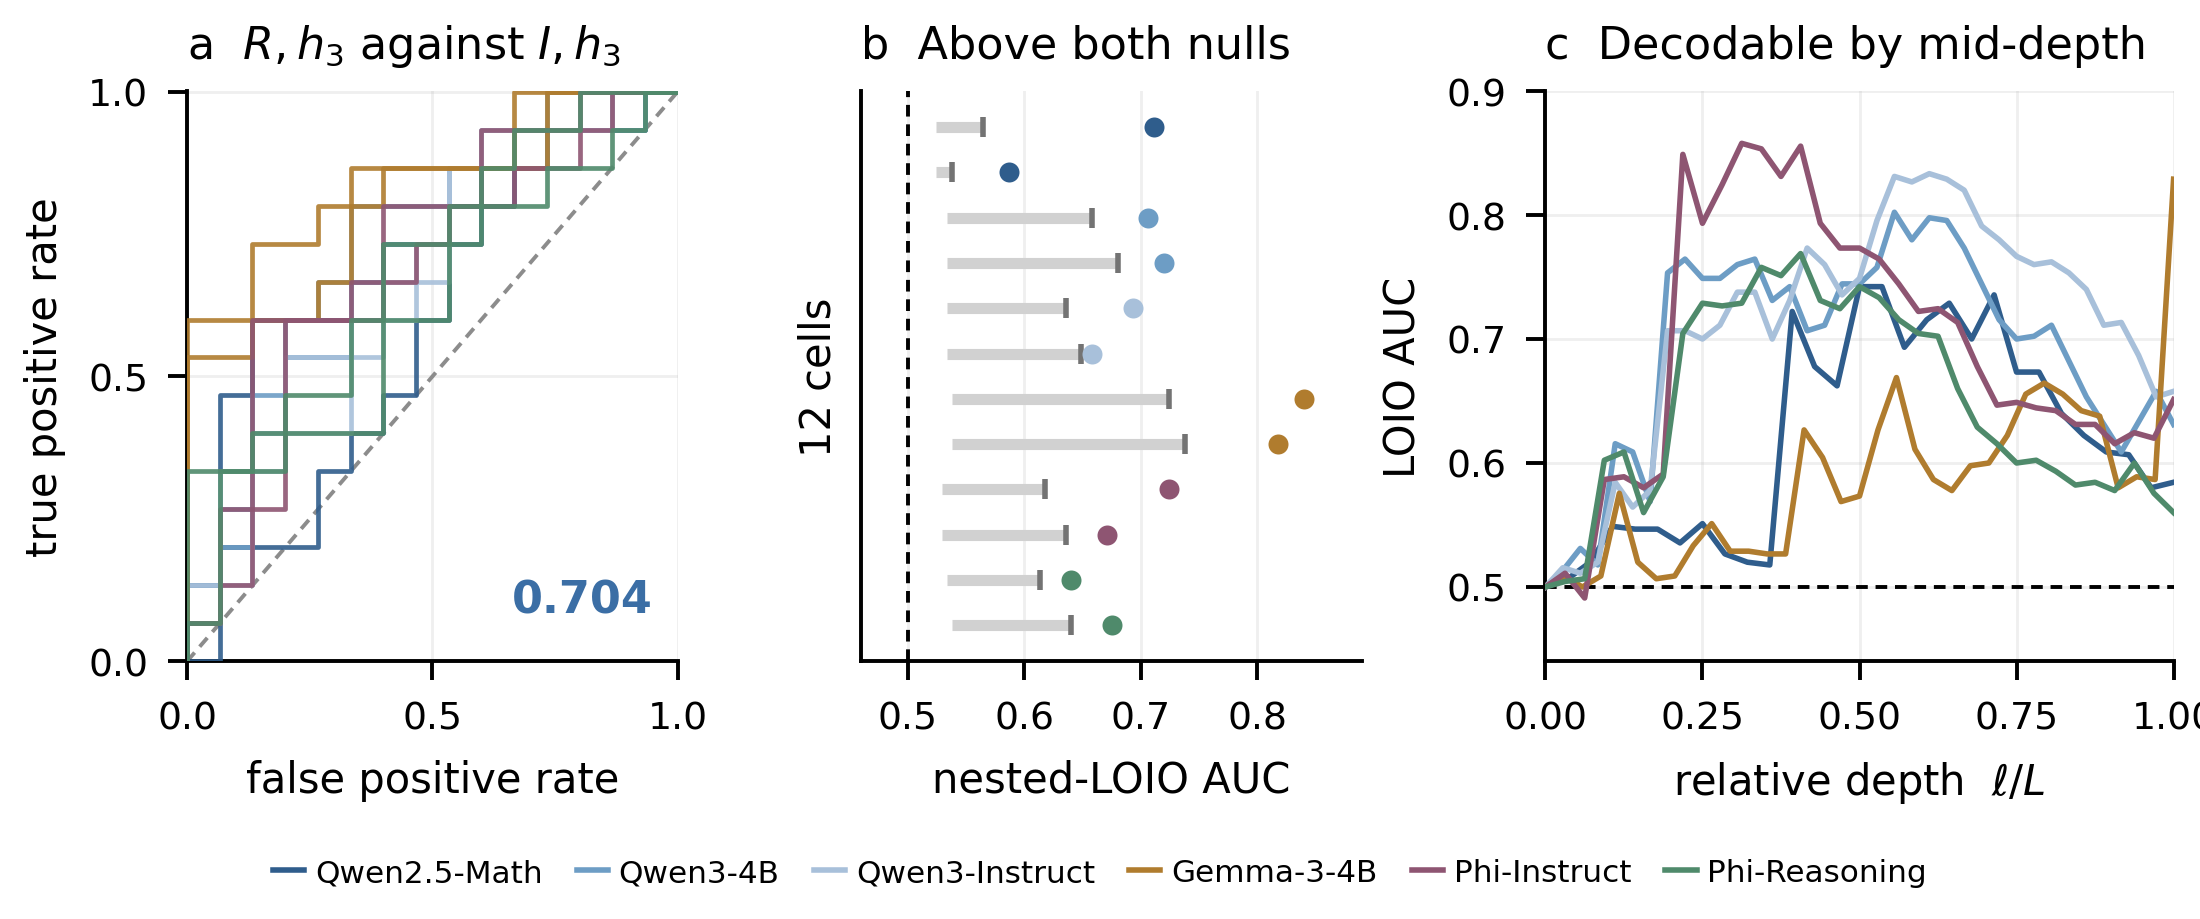

**figS2_intervention_detail.png**

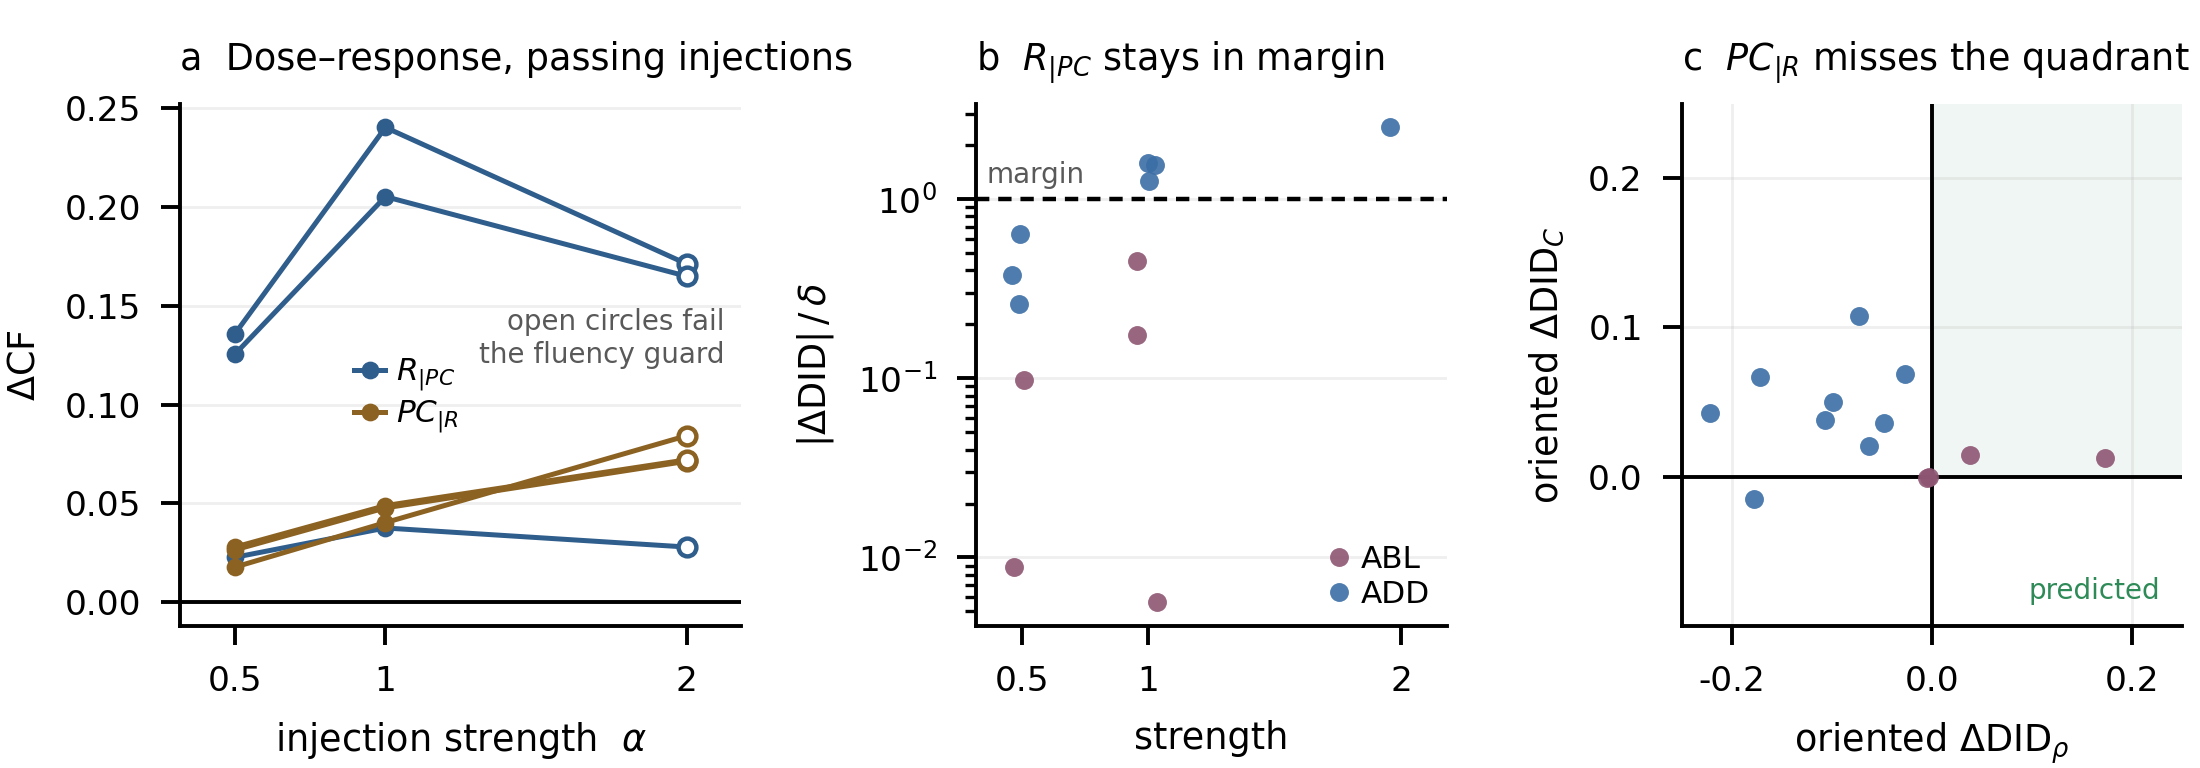

In [6]:
for f, w in [('fig1_behavior.png', 760), ('fig2_representation.png', 820), ('fig3_cf_intervention.png', 900), ('figS1_decoding.png', 900), ('figS2_intervention_detail.png', 900)]:
    display(Markdown(f'**{f}**')); show_figure(f, w)